In [2]:
from watts.plugin_cyclus import ResultsCyclus

In [3]:
from watts.parameters import Parameters
from watts.results import ExecInfo, Results
from watts.plugin_cyclus import CyclusOutput
inputs = []
outputs = ['./nuc46_nz50_ot1.sqlite']

obj = ResultsCyclus(Parameters(), ExecInfo(1, 'cyclus', 'name', 1),
                    inputs, outputs)

In [4]:
reactors = obj.reactors

In [5]:
named_reactors = ['AP1000', 'VOYGR', '12VOYGR' 'Natrium', 'XE100', '4XE100']

In [6]:
legacy_protos = [q for q in obj.reactors.values() if q not in named_reactors]



In [16]:
def aggregate_smr(d):
    # 4XE100 and 12VOYGR
    # because we can't have that many agents deployed
    if '12VOYGR' in d:
        if 'VOYGR' in d:
            d['VOYGR'] += d.pop('12VOYGR')
        else:
            d['VOYGR'] = d.pop('12VOYGR')
    if '4XE100' in d:
        if 'XE100' in d:
            d['XE100'] += d.pop('4XE100')
        else:
            d['XE100'] = d.pop('4XE100')
    return d

In [17]:
data_dict = {}

In [18]:
import numpy as np
which = 'natu'
data_dict[which] = {}
for proto in named_reactors:
    if proto in reactors.values():
        data_dict[which][proto] = obj.obj.stock_fuel_natu(proto, 0.00711, 0.0025)

data_dict[which]['legacy'] = obj.obj.stock_fuel_natu(legacy_protos, 0.00711, 0.0025)

data_dict[which] = aggregate_smr(data_dict[which])


	Processing prototype: AP1000


/home/4ib/anaconda3/envs/env_neutronics/lib/python3.7/site-packages/watts-0.1-py3.7.egg/watts/plugin_cyclus.py:503: RuntimeWarning: invalid value encountered in true_divide
  return np.nan_to_num(u235_mass_annual / all_mass_annual, nan=0)
/home/4ib/anaconda3/envs/env_neutronics/lib/python3.7/site-packages/watts-0.1-py3.7.egg/watts/plugin_cyclus.py:435: RuntimeWarning: invalid value encountered in true_divide
  return sum(flow_into.values()), np.nan_to_num(tot_u235 / sum(flow_into.values()), nan=0)


	Processing prototype: ['NINE MILE POINT-1', 'DRESDEN-2', 'GINNA', 'POINT BEACH-1', 'ROBINSON-2', 'MONTICELLO', 'DRESDEN-3', 'PALISADES', 'POINT BEACH-2', 'TURKEY POINT-3', 'SURRY-1', 'QUAD CITIES-1', 'QUAD CITIES-2', 'SURRY-2', 'OCONEE-1', 'TURKEY POINT-4', 'PRAIRIE ISLAND-1', 'PEACH BOTTOM-2', 'COOPER', 'BROWNS FERRY-1', 'OCONEE-2', 'OCONEE-3', 'PEACH BOTTOM-3', 'ANO-1', 'PRAIRIE ISLAND-2', 'BROWNS FERRY-2', 'CALVERT CLIFFS-1', 'FITZPATRICK', 'COOK-1', 'BRUNSWICK-2', 'HATCH-1', 'MILLSTONE-2', 'INDIAN POINT-3', 'BEAVER VALLEY-1', 'ST. LUCIE-1', 'BROWNS FERRY-3', 'BRUNSWICK-1', 'CALVERT CLIFFS-2', 'SALEM-1', 'FARLEY-1', 'NORTH ANNA-1', 'COOK-2', 'DAVIS BESSE-1', 'HATCH-2', 'ANO-2', 'NORTH ANNA-2', 'SEQUOYAH-1', 'FARLEY-2', 'SALEM-2', 'MCGUIRE-1', 'SEQUOYAH-2', 'SUSQUEHANNA-1', 'ST. LUCIE-2', 'SUMMER-1', 'LASALLE-1', 'MCGUIRE-2', 'LASALLE-2', 'COLUMBIA', 'CALLAWAY-1', 'SUSQUEHANNA-2', 'DIABLO CANYON-1', 'CATAWBA-1', 'GRAND GULF-1', 'WOLF CREEK', 'WATERFORD-3', 'BYRON-1', 'LIMERICK-1', '

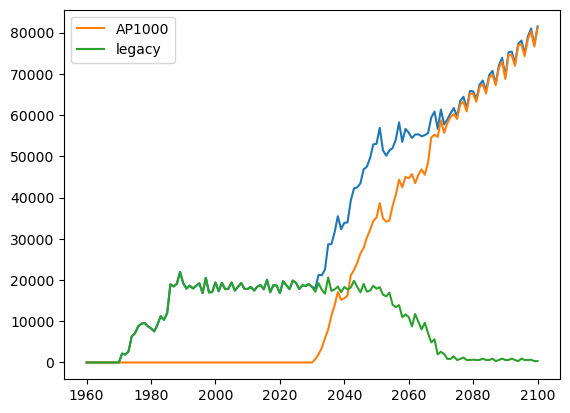

In [19]:
import matplotlib.pyplot as plt
plt.plot(obj.time_dict['years'][::12], sum(data_dict[which].values())/1e3)
for k,v in data_dict[which].items():
    plt.plot(obj.time_dict['years'][::12], v/1e3, label=k)
plt.legend()

In [20]:
import numpy as np
which = 'swu'
data_dict[which] = {}
for proto in named_reactors:
    if proto in reactors.values():
        data_dict[which][proto] =  obj.obj.stock_fuel_swu(proto, 0.00711, 0.0025)

data_dict[which]['legacy'] = obj.obj.stock_fuel_swu(legacy_protos, 0.00711, 0.0025)

data_dict[which] = aggregate_smr(data_dict[which])



	Processing prototype: AP1000


/home/4ib/anaconda3/envs/env_neutronics/lib/python3.7/site-packages/watts-0.1-py3.7.egg/watts/plugin_cyclus.py:503: RuntimeWarning: invalid value encountered in true_divide
  return np.nan_to_num(u235_mass_annual / all_mass_annual, nan=0)
/home/4ib/anaconda3/envs/env_neutronics/lib/python3.7/site-packages/watts-0.1-py3.7.egg/watts/plugin_cyclus.py:435: RuntimeWarning: invalid value encountered in true_divide
  return sum(flow_into.values()), np.nan_to_num(tot_u235 / sum(flow_into.values()), nan=0)
/home/4ib/anaconda3/envs/env_neutronics/lib/python3.7/site-packages/watts-0.1-py3.7.egg/watts/plugin_cyclus.py:451: RuntimeWarning: divide by zero encountered in log
  return (2*x-1)*np.log(x/(1-x))
/home/4ib/anaconda3/envs/env_neutronics/lib/python3.7/site-packages/watts-0.1-py3.7.egg/watts/plugin_cyclus.py:453: RuntimeWarning: invalid value encountered in multiply
  return fuel_mass_flow * v(enr) + tails * v(tails_assay) - natu * v(natu_assay)


	Processing prototype: ['NINE MILE POINT-1', 'DRESDEN-2', 'GINNA', 'POINT BEACH-1', 'ROBINSON-2', 'MONTICELLO', 'DRESDEN-3', 'PALISADES', 'POINT BEACH-2', 'TURKEY POINT-3', 'SURRY-1', 'QUAD CITIES-1', 'QUAD CITIES-2', 'SURRY-2', 'OCONEE-1', 'TURKEY POINT-4', 'PRAIRIE ISLAND-1', 'PEACH BOTTOM-2', 'COOPER', 'BROWNS FERRY-1', 'OCONEE-2', 'OCONEE-3', 'PEACH BOTTOM-3', 'ANO-1', 'PRAIRIE ISLAND-2', 'BROWNS FERRY-2', 'CALVERT CLIFFS-1', 'FITZPATRICK', 'COOK-1', 'BRUNSWICK-2', 'HATCH-1', 'MILLSTONE-2', 'INDIAN POINT-3', 'BEAVER VALLEY-1', 'ST. LUCIE-1', 'BROWNS FERRY-3', 'BRUNSWICK-1', 'CALVERT CLIFFS-2', 'SALEM-1', 'FARLEY-1', 'NORTH ANNA-1', 'COOK-2', 'DAVIS BESSE-1', 'HATCH-2', 'ANO-2', 'NORTH ANNA-2', 'SEQUOYAH-1', 'FARLEY-2', 'SALEM-2', 'MCGUIRE-1', 'SEQUOYAH-2', 'SUSQUEHANNA-1', 'ST. LUCIE-2', 'SUMMER-1', 'LASALLE-1', 'MCGUIRE-2', 'LASALLE-2', 'COLUMBIA', 'CALLAWAY-1', 'SUSQUEHANNA-2', 'DIABLO CANYON-1', 'CATAWBA-1', 'GRAND GULF-1', 'WOLF CREEK', 'WATERFORD-3', 'BYRON-1', 'LIMERICK-1', '

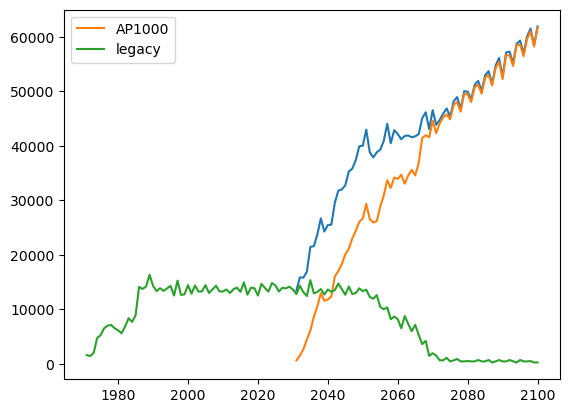

In [21]:
import matplotlib.pyplot as plt
plt.plot(obj.time_dict['years'][::12], sum(data_dict[which].values())/1e3)
for k,v in data_dict[which].items():
    plt.plot(obj.time_dict['years'][::12], v/1e3, label=k)
plt.legend()

In [23]:
# get fuel demand
which = 'fuel'
data_dict[which] = {}
for proto in named_reactors:
    if proto in reactors.values():
        data_dict[which][proto] = obj.obj.process_prototype(proto, False)[1]['receiving']
        data_dict[which][proto] = list(data_dict[which][proto].values())[0]

data_dict[which]['legacy'] = sum(obj.obj.process_prototype(legacy_protos, False)[1]['receiving'].values())


data_dict[which] = aggregate_smr(data_dict[which])


	Processing prototype: AP1000
	Processing prototype: ['NINE MILE POINT-1', 'DRESDEN-2', 'GINNA', 'POINT BEACH-1', 'ROBINSON-2', 'MONTICELLO', 'DRESDEN-3', 'PALISADES', 'POINT BEACH-2', 'TURKEY POINT-3', 'SURRY-1', 'QUAD CITIES-1', 'QUAD CITIES-2', 'SURRY-2', 'OCONEE-1', 'TURKEY POINT-4', 'PRAIRIE ISLAND-1', 'PEACH BOTTOM-2', 'COOPER', 'BROWNS FERRY-1', 'OCONEE-2', 'OCONEE-3', 'PEACH BOTTOM-3', 'ANO-1', 'PRAIRIE ISLAND-2', 'BROWNS FERRY-2', 'CALVERT CLIFFS-1', 'FITZPATRICK', 'COOK-1', 'BRUNSWICK-2', 'HATCH-1', 'MILLSTONE-2', 'INDIAN POINT-3', 'BEAVER VALLEY-1', 'ST. LUCIE-1', 'BROWNS FERRY-3', 'BRUNSWICK-1', 'CALVERT CLIFFS-2', 'SALEM-1', 'FARLEY-1', 'NORTH ANNA-1', 'COOK-2', 'DAVIS BESSE-1', 'HATCH-2', 'ANO-2', 'NORTH ANNA-2', 'SEQUOYAH-1', 'FARLEY-2', 'SALEM-2', 'MCGUIRE-1', 'SEQUOYAH-2', 'SUSQUEHANNA-1', 'ST. LUCIE-2', 'SUMMER-1', 'LASALLE-1', 'MCGUIRE-2', 'LASALLE-2', 'COLUMBIA', 'CALLAWAY-1', 'SUSQUEHANNA-2', 'DIABLO CANYON-1', 'CATAWBA-1', 'GRAND GULF-1', 'WOLF CREEK', 'WATERFORD-

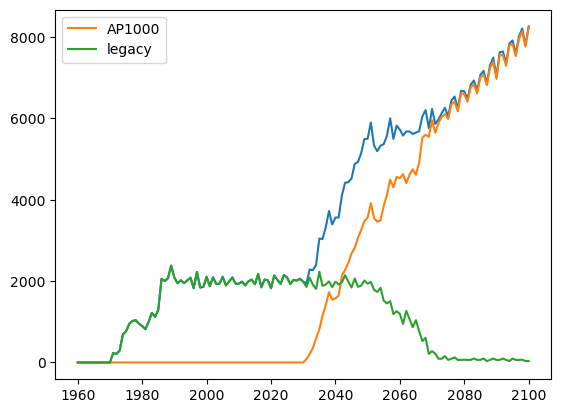

In [24]:
import matplotlib.pyplot as plt
plt.plot(obj.time_dict['years'][::12], sum(data_dict[which].values())/1e3)
for k,v in data_dict[which].items():
    plt.plot(obj.time_dict['years'][::12], v/1e3, label=k)
plt.legend()